# Classification of Gastrointestinal Medical Images for Disease Diagnosis

This project uses deep learning and transfer learning to classify gastrointestinal medical images into four classes:
- Normal
- Polyps
- Esophagitis
- Ulcerative Colitis

# Quick Start

In [1]:
# 1) Imports

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_from_disk
from torchvision import transforms
from torchvision.models import inception_v3, Inception_V3_Weights
from torch.utils.data import Dataset, DataLoader

In [2]:
# 2) Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 3) Load saved dataset splits

splits_path = "/content/drive/MyDrive/GI_Project/dataset_splits_no_leakage"

dataset_splits = load_from_disk(splits_path)

train_dataset = dataset_splits["train"]
valid_dataset = dataset_splits["validation"]
test_dataset = dataset_splits["test"]

print("Train:", len(train_dataset))
print("Validation:", len(valid_dataset))
print("Test:", len(test_dataset))

Train: 3683
Validation: 789
Test: 790


In [4]:
# 4) Image Transform

image_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transform is ready.")

Image transform is ready.


In [5]:
# 5) Custom Dataset Class

class GIDataset(Dataset):

    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        item = self.dataset[idx]

        image = item["image"]
        label = item["label"]

        if self.transform:
            image = self.transform(image)

        return image, label

print("GIDataset class is ready.")

GIDataset class is ready.


In [6]:
# 6) Create datasets

train_data = GIDataset(
    train_dataset,
    transform=image_transform
)

valid_data = GIDataset(
    valid_dataset,
    transform=image_transform
)

test_data = GIDataset(
    test_dataset,
    transform=image_transform
)

print("Datasets are ready.")

Datasets are ready.


In [7]:
# 7) DataLoaders

batch_size = 32

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = DataLoader(
    valid_data,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders are ready.")

DataLoaders are ready.


In [8]:
# 8) Build InceptionV3 structure

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = Inception_V3_Weights.DEFAULT

model = inception_v3(
    weights=weights,
    aux_logits=True
)

num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    4
)

model = model.to(device)

print("Device:", device)
print("Model structure is ready.")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 58.7MB/s] 


Device: cuda
Model structure is ready.


In [9]:
# 9) Load FINAL trained model

final_model_path = (
    "/content/drive/MyDrive/GI_Project/"
    "final_inceptionv3_model.pth"
)

model.load_state_dict(
    torch.load(
        final_model_path,
        map_location=device
    )
)

model.eval()

print("Final trained model loaded successfully!")

Final trained model loaded successfully!


In [10]:
# 10) Load saved training history

import json

history_path = (
    "/content/drive/MyDrive/GI_Project/"
    "training_history.json"
)

with open(history_path, "r") as f:
    history = json.load(f)

print("Training history loaded successfully!")
print(history.keys())

Training history loaded successfully!
dict_keys(['train_loss', 'train_acc', 'valid_loss', 'valid_acc'])


In [11]:
# 11) Install and import Grad-CAM

!pip install -q grad-cam

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

print("Grad-CAM library is ready.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 83.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Grad-CAM library is ready.


In [12]:
# 12) Grad-CAM Setup

image_tensor, true_label = test_data[0]

input_tensor = image_tensor.unsqueeze(0).to(device)
input_tensor.requires_grad_(True)

target_layers = [model.Mixed_7c]

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

print("Quick Start completed successfully!")
print("Device:", device)
print("True Label:", true_label)
print("Input shape:", input_tensor.shape)

Quick Start completed successfully!
Device: cuda
True Label: 3
Input shape: torch.Size([1, 3, 299, 299])


# Quick END

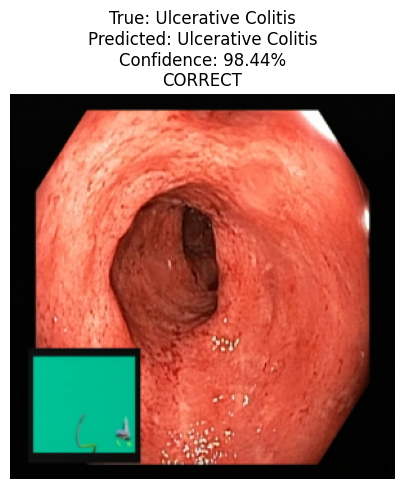

Test image index: 274
True class: Ulcerative Colitis
Predicted class: Ulcerative Colitis
Confidence: 98.44%
Result: CORRECT


In [13]:
# Random Test

import random
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "Normal",
    "Polyps",
    "Esophagitis",
    "Ulcerative Colitis"
]

# اختيار صورة عشوائية من Test Set
random_index = random.randint(0, len(test_data) - 1)

image_tensor, true_label = test_data[random_index]

input_tensor = image_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():

    outputs = model(input_tensor)

    if hasattr(outputs, "logits"):
        outputs = outputs.logits

    probabilities = F.softmax(outputs, dim=1)

    confidence, predicted_label = torch.max(
        probabilities,
        dim=1
    )

predicted_label = predicted_label.item()
confidence = confidence.item() * 100

# اعادة الصورة الى شكل طبيعي للعرض
image_display = (
    image_tensor
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

# تحديد هل التنبؤ صحيح
is_correct = predicted_label == true_label

result_text = "CORRECT" if is_correct else "WRONG"

# عرض الصورة
plt.figure(figsize=(6, 5))

plt.imshow(image_display)
plt.axis("off")

plt.title(
    f"True: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {confidence:.2f}%\n"
    f"{result_text}"
)

plt.show()

print("Test image index:", random_index)
print("True class:", class_names[true_label])
print("Predicted class:", class_names[predicted_label])
print(f"Confidence: {confidence:.2f}%")
print("Result:", result_text)

Saving P1.jpeg to P1 (2).jpeg


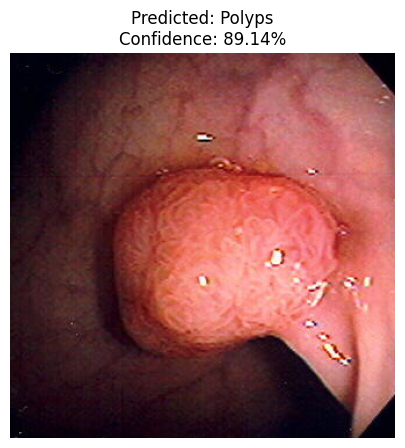

Predicted class: Polyps
Confidence: 89.14%


In [ ]:
from google.colab import files
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# رفع صورة
uploaded = files.upload()

image_name = list(uploaded.keys())[0]


external_image = Image.open(image_name).convert("RGB")


input_tensor = image_transform(external_image)
input_tensor = input_tensor.unsqueeze(0).to(device)

class_names = [
    "Normal",
    "Polyps",
    "Esophagitis",
    "Ulcerative Colitis"
]

# Prediction
model.eval()

with torch.no_grad():

    outputs = model(input_tensor)

    if hasattr(outputs, "logits"):
        outputs = outputs.logits

    probabilities = F.softmax(outputs, dim=1)

    confidence, predicted_label = torch.max(
        probabilities,
        dim=1
    )

predicted_label = predicted_label.item()
confidence = confidence.item() * 100

# عرض الصورة والنتيجة
plt.figure(figsize=(6, 5))
plt.imshow(external_image)
plt.axis("off")

plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

print("Predicted class:", class_names[predicted_label])
print(f"Confidence: {confidence:.2f}%")

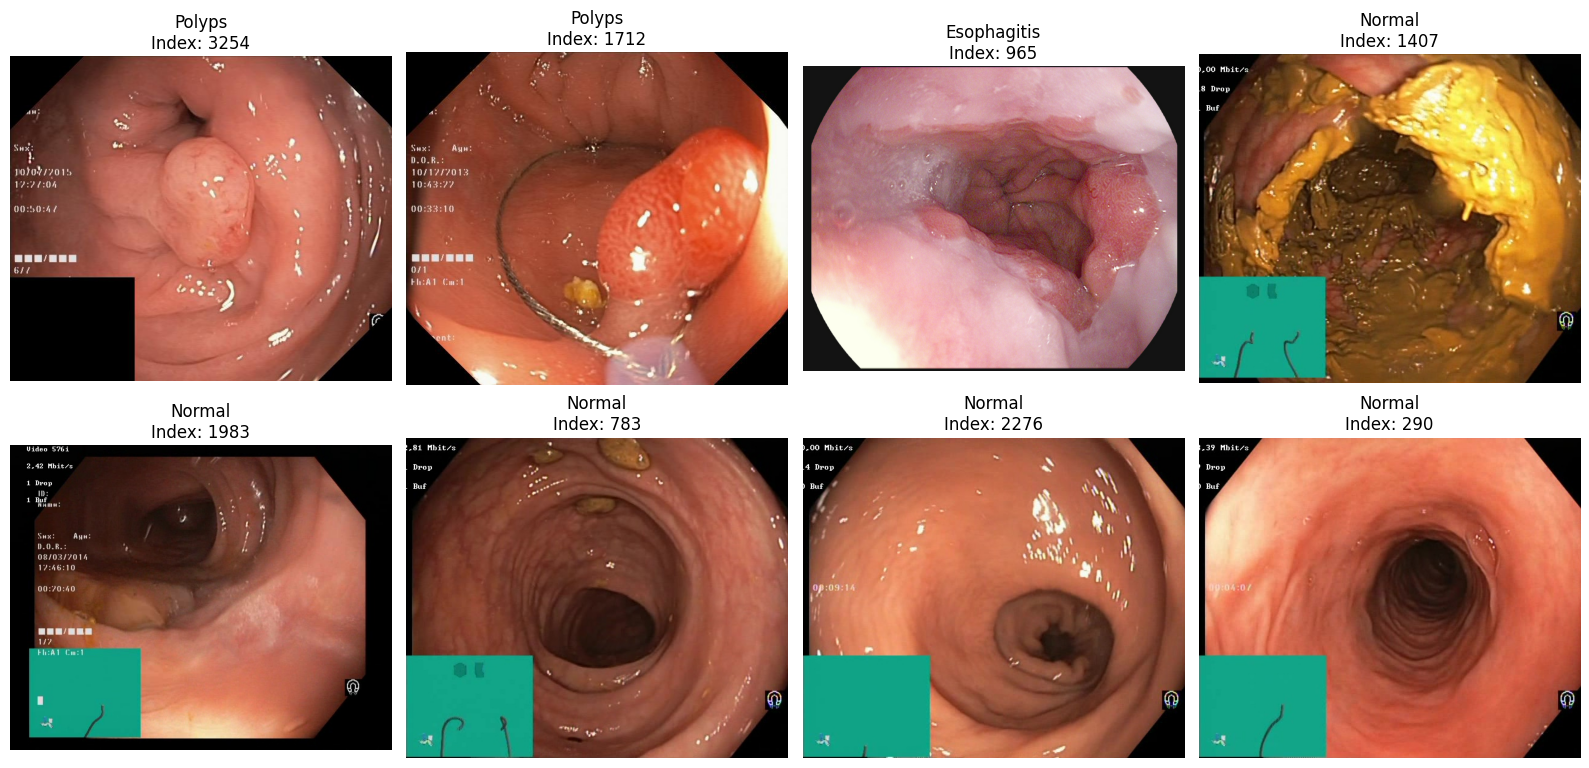

In [ ]:
# عرض صور عشوائية من مجموعة التدريب

import random
import matplotlib.pyplot as plt

num_images = 8

random_indices = random.sample(
    range(len(train_dataset)),
    num_images
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, idx in zip(axes.flatten(), random_indices):

    sample = train_dataset[idx]

    image = sample["image"]
    class_name = sample["source"]
    img_id = sample["img_id"]

    ax.imshow(image)
    ax.set_title(
        f"{class_name}\nIndex: {idx}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import os

project_path = "/content/drive/MyDrive/GI_Project"
os.makedirs(project_path, exist_ok=True)

print("Project folder is ready:", project_path)

Project folder is ready: /content/drive/MyDrive/GI_Project


In [15]:
!pip install -q datasets scikit-learn matplotlib seaborn

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

import torch
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [17]:
dataset = load_dataset("SimulaMet-HOST/Kvasir-VQA")

print(dataset)

README.md:   0%|          | 0.00/5.13k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

data/00000.parquet: reconstructing file:   0%|          |  0.00B / 26.8MB            

data/00000.parquet: downloading bytes:           |  0.00B            

data/00001.parquet: reconstructing file:   0%|          |  0.00B / 26.2MB            

... (58 outputs left out)

data/00030.parquet: downloading bytes:           |  0.00B            

Generating raw split:   0%|          | 0/58849 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/30 [00:00<?, ?it/s]

DatasetDict({
    raw: Dataset({
        features: ['image', 'source', 'question', 'answer', 'img_id'],
        num_rows: 58849
    })
})


In [18]:
target_classes = ["Normal", "Polyps", "Esophagitis", "Ulcerative Colitis"]

print("Target classes:")
for cls in target_classes:
    print("-", cls)

Target classes:
- Normal
- Polyps
- Esophagitis
- Ulcerative Colitis


In [19]:
filtered_dataset = dataset["raw"].filter(
    lambda example: example["source"] in target_classes
)

print(filtered_dataset)

Filter:   0%|          | 0/58849 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'source', 'question', 'answer', 'img_id'],
    num_rows: 49652
})


In [20]:
from collections import Counter

class_counts = Counter(filtered_dataset["source"])

print("Number of images per class:")
for cls, count in class_counts.items():
    print(cls, ":", count)

Number of images per class:
Ulcerative Colitis : 16890
Polyps : 13539
Esophagitis : 16723
Normal : 2500


In [21]:
# تحويل اسماء الأصناف الى ارقام

label2id = {
    "Normal": 0,
    "Polyps": 1,
    "Esophagitis": 2,
    "Ulcerative Colitis": 3
}

id2label = {
    0: "Normal",
    1: "Polyps",
    2: "Esophagitis",
    3: "Ulcerative Colitis"
}

print(label2id)

{'Normal': 0, 'Polyps': 1, 'Esophagitis': 2, 'Ulcerative Colitis': 3}


In [22]:
#لجعل لصور بحجم 299 × 299

from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transform is ready.")

Image transform is ready.


In [23]:
from torch.utils.data import Dataset

class GIDataset(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        image = item["image"]
        label = item["label"]

        if self.transform:
            image = self.transform(image)

        return image, label

print("Custom dataset class created.")

Custom dataset class created.


In [24]:
train_data = GIDataset(train_dataset, transform=image_transform)
valid_data = GIDataset(valid_dataset, transform=image_transform)
test_data = GIDataset(test_dataset, transform=image_transform)

print("Datasets are ready.")
print("Train:", len(train_data))
print("Validation:", len(valid_data))
print("Test:", len(test_data))

Datasets are ready.
Train: 3683
Validation: 789
Test: 790


In [25]:
#استدعاء الطبقات والنموزج

import torch.nn as nn
from torchvision.models import inception_v3, Inception_V3_Weights

In [26]:
# تحميل نموذج InceptionV3 المدرب مسبقًا على ImageNet

weights = Inception_V3_Weights.DEFAULT

model = inception_v3(
    weights=weights,
    aux_logits=True
)

In [27]:
# تجميد الطبقات القديمة

for param in model.parameters():
    param.requires_grad = False

print("Base model frozen.")

Base model frozen.


In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU Name:", torch.cuda.get_device_name(0))

Device: cuda
GPU Name: Tesla T4


In [29]:
# اعطاء النموزج 32 صورة دفعه واحده

from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = DataLoader(
    valid_data,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders are ready.")

DataLoaders are ready.


In [30]:
# دالة التدريب والتقييم - متوافقة مع InceptionV3

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)


        outputs = model(images)


        if hasattr(outputs, "logits"):
            outputs = outputs.logits

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(train_loader)
    accuracy = correct / total

    return avg_loss, accuracy


def evaluate(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)


            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(data_loader)
    accuracy = correct / total

    return avg_loss, accuracy


print("Training and evaluation functions are ready.")

Training and evaluation functions are ready.


In [31]:
#  تجهيز نموذج InceptionV3 بشكل نظيف للتدريب الصحيح

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import inception_v3, Inception_V3_Weights


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# تحميل InceptionV3 المدرب مسبقًا على ImageNet
weights = Inception_V3_Weights.DEFAULT

model = inception_v3(
    weights=weights,
    aux_logits=True
)


# تجميد جميع الطبقات القديمة
for param in model.parameters():
    param.requires_grad = False


# استبدال آخر طبقة بطبقة جديدة لأربع فئات
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 4)

model = model.to(device)


# Loss
criterion = nn.CrossEntropyLoss()



# انشاء Optimizer بعد انشاء model.fc الجديدة
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)


print("Fresh model is ready.")
print("Final layer:", model.fc)

Device: cuda
GPU: Tesla T4
Fresh model is ready.
Final layer: Linear(in_features=2048, out_features=4, bias=True)


In [32]:
!pip install grad-cam

In [33]:
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

In [34]:
# اخر طبقة Convolution في InceptionV3

target_layers = [model.Mixed_7c]

print(target_layers)

[InceptionE(
  (branch1x1): BasicConv2d(
    (conv): Conv2d(2048, 320, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(320, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3_1): BasicConv2d(
    (conv): Conv2d(2048, 384, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(384, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3_2a): BasicConv2d(
    (conv): Conv2d(384, 384, kernel_size=(1, 3), stride=(1, 1), padding=(0, 1), bias=False)
    (bn): BatchNorm2d(384, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3_2b): BasicConv2d(
    (conv): Conv2d(384, 384, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0), bias=False)
    (bn): BatchNorm2d(384, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3dbl_1): BasicConv2d(
    (conv): Conv2d(2048, 448, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(448, eps=0.001, m

In [35]:
import os

results_path = "/content/drive/MyDrive/GI_Project/Results"

os.makedirs(results_path, exist_ok=True)

print("Results folder is ready:")
print(results_path)

Results folder is ready:
/content/drive/MyDrive/GI_Project/Results


In [ ]:
# ==========================================
# Training
# Training Run for Saving History
# ==========================================

import json
import torch


# ----------------------------
# دالة التدريب
# ----------------------------
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)


        if hasattr(outputs, "logits"):
            outputs = outputs.logits

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(train_loader)
    accuracy = correct / total

    return avg_loss, accuracy


# ----------------------------
# دالة التقييم
# ----------------------------
def evaluate(model, data_loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(data_loader)
    accuracy = correct / total

    return avg_loss, accuracy


# ----------------------------
# اعداد التدريب
# ----------------------------

num_epochs = 5

history = {
    "train_loss": [],
    "train_acc": [],
    "valid_loss": [],
    "valid_acc": []
}

best_valid_acc = 0.0


history_model_path = (
    "/content/drive/MyDrive/GI_Project/"
    "best_inceptionv3_history_run.pth"
)

history_path = (
    "/content/drive/MyDrive/GI_Project/"
    "training_history.json"
)


# ----------------------------
# التدريب
# ----------------------------

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    valid_loss, valid_acc = evaluate(
        model,
        valid_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["valid_loss"].append(valid_loss)
    history["valid_acc"].append(valid_acc)

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f}"
    )
    print(
        f"Valid Loss: {valid_loss:.4f} | "
        f"Valid Acc: {valid_acc:.4f}"
    )

    # حفظ افضل نموذج لهذا التدريب
    if valid_acc > best_valid_acc:

        best_valid_acc = valid_acc

        torch.save(
            model.state_dict(),
            history_model_path
        )

        print("New best history-run model saved")


    # حفظ History بعد كل Epoch
    with open(history_path, "w") as f:
        json.dump(history, f, indent=4)

    print("History saved to Drive.")


print("\nTraining Finished.")
print(f"Best Validation Accuracy: {best_valid_acc:.4f}")
print("History file:", history_path)

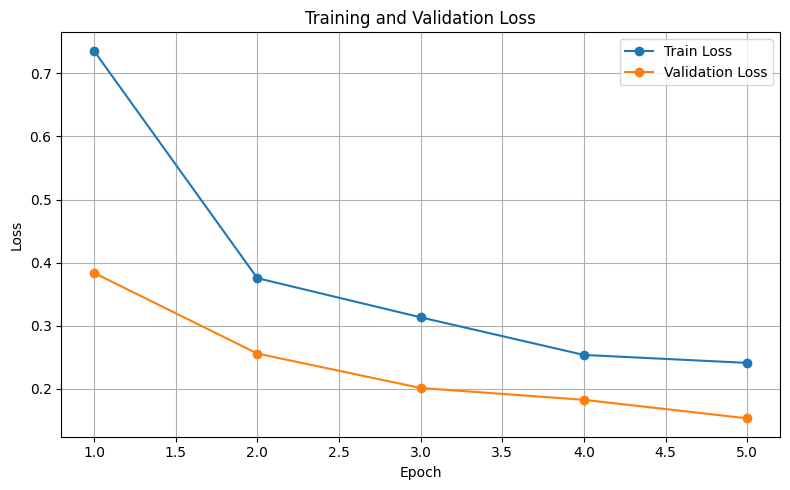

Loss curve saved to:
/content/drive/MyDrive/GI_Project/Results/loss_curve.png


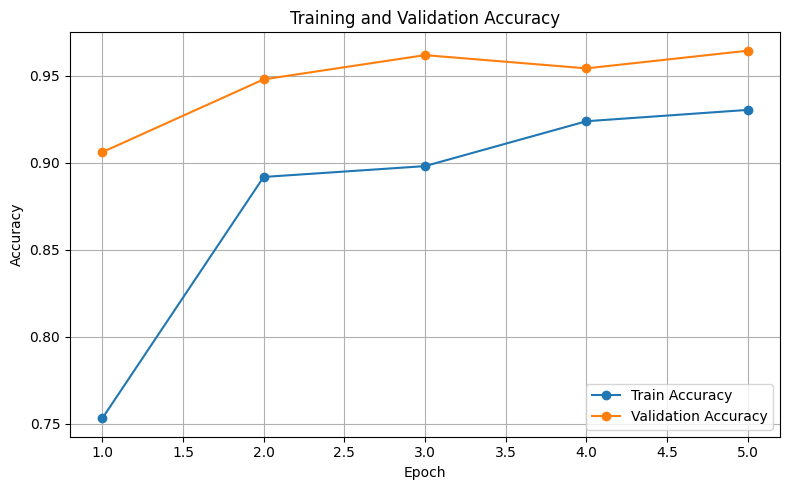

Accuracy curve saved to:
/content/drive/MyDrive/GI_Project/Results/accuracy_curve.png


In [ ]:
# ==========================================
# رسم منحنيات التدريب
# ==========================================

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# -------------------------
# Loss Curve
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["valid_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_path = "/content/drive/MyDrive/GI_Project/Results/loss_curve.png"

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss curve saved to:")
print(loss_path)


# -------------------------
# Accuracy Curve
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_acc"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history["valid_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_path = "/content/drive/MyDrive/GI_Project/Results/accuracy_curve.png"

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy curve saved to:")
print(accuracy_path)

In [ ]:
# تحميل افضل نموذج من training history run

history_model_path = "/content/drive/MyDrive/GI_Project/best_inceptionv3_history_run.pth"

model.load_state_dict(
    torch.load(history_model_path, map_location=device)
)

model = model.to(device)
model.eval()

print("Best history-run model loaded successfully!")

Best history-run model loaded successfully!


In [ ]:
# تقييم النموذج الجديد على Test Set

test_loss_new, test_acc_new = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"New Test Loss: {test_loss_new:.4f}")
print(f"New Test Accuracy: {test_acc_new:.4f}")
print(f"New Test Accuracy (%): {test_acc_new * 100:.2f}%")

New Test Loss: 0.1589
New Test Accuracy: 0.9658
New Test Accuracy (%): 96.58%


In [ ]:
# حفظ النموذج الجديد كالنموذج النهائي للمشروع

final_model_path = "/content/drive/MyDrive/GI_Project/final_inceptionv3_model.pth"

torch.save(
    model.state_dict(),
    final_model_path
)

print("Final model saved successfully!")
print(final_model_path)

Final model saved successfully!
/content/drive/MyDrive/GI_Project/final_inceptionv3_model.pth


In [ ]:
# ==========================================
# Final Evaluation: Predictions on Test Set
# ==========================================

from sklearn.metrics import confusion_matrix, classification_report
import torch

all_labels_final = []
all_predictions_final = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        if hasattr(outputs, "logits"):
            outputs = outputs.logits

        _, predicted = torch.max(outputs, 1)

        all_labels_final.extend(labels.cpu().numpy())
        all_predictions_final.extend(predicted.cpu().numpy())

print("Final predictions collected successfully!")

Final predictions collected successfully!


In [ ]:
# ==========================================
# Final Classification Report
# ==========================================

class_names = [
    "Normal",
    "Polyps",
    "Esophagitis",
    "Ulcerative Colitis"
]

final_report = classification_report(
    all_labels_final,
    all_predictions_final,
    target_names=class_names,
    digits=4
)

print(final_report)

                    precision    recall  f1-score   support

            Normal     0.9730    0.9627    0.9678       375
            Polyps     1.0000    0.9416    0.9699       137
       Esophagitis     0.9714    0.9855    0.9784       138
Ulcerative Colitis     0.9133    0.9786    0.9448       140

          accuracy                         0.9658       790
         macro avg     0.9645    0.9671    0.9652       790
      weighted avg     0.9669    0.9658    0.9660       790



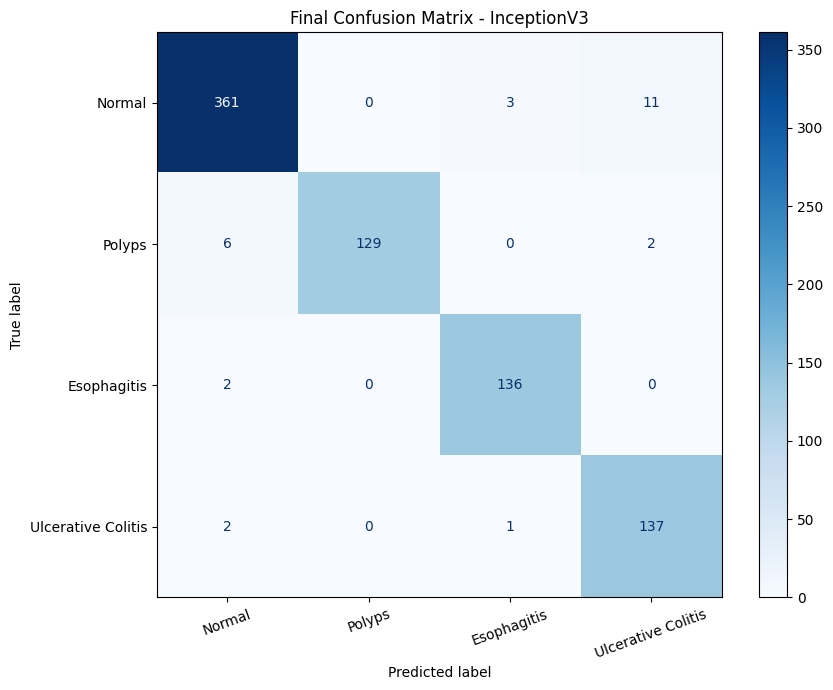

Final Confusion Matrix saved to:
/content/drive/MyDrive/GI_Project/Results/final_confusion_matrix.png


In [ ]:
# ==========================================
# Final Confusion Matrix
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_final = confusion_matrix(
    all_labels_final,
    all_predictions_final
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Final Confusion Matrix - InceptionV3")
plt.xticks(rotation=20)
plt.tight_layout()

final_cm_path = (
    "/content/drive/MyDrive/GI_Project/Results/"
    "final_confusion_matrix.png"
)

plt.savefig(
    final_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final Confusion Matrix saved to:")
print(final_cm_path)

In [ ]:
# تحديث ملخص النتائج النهائية

results_summary = """
GI Medical Image Classification - FINAL Results

Model:
InceptionV3 using Transfer Learning

Dataset:
- Unique images: 5262
- Train: 3683
- Validation: 789
- Test: 790
- Data leakage check: 0 overlap between Train, Validation, and Test

Training:
- Epochs: 5
- Best Validation Accuracy: 96.45%

Final Test Results:
- Test Loss: 0.1589
- Test Accuracy: 96.58%

Classification Report:

Normal
Precision: 97.30%
Recall: 96.27%
F1-score: 96.78%

Polyps
Precision: 100.00%
Recall: 94.16%
F1-score: 96.99%

Esophagitis
Precision: 97.14%
Recall: 98.55%
F1-score: 97.84%

Ulcerative Colitis
Precision: 91.33%
Recall: 97.86%
F1-score: 94.48%

Macro Average F1-score: 96.52%
Weighted Average F1-score: 96.60%

Explainability:
Grad-CAM was used to visualize the image regions that contributed
most strongly to the model predictions.
"""

summary_path = "/content/drive/MyDrive/GI_Project/Results/results_summary.txt"

with open(summary_path, "w") as file:
    file.write(results_summary)

print("Final results summary updated successfully!")
print(summary_path)

Final results summary updated successfully!
/content/drive/MyDrive/GI_Project/Results/results_summary.txt


In [ ]:
# ==========================================
# Final Grad-CAM Setup
# ==========================================

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()

target_layers = [model.Mixed_7c]

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

print("Final Grad-CAM is ready!")

Final Grad-CAM is ready!


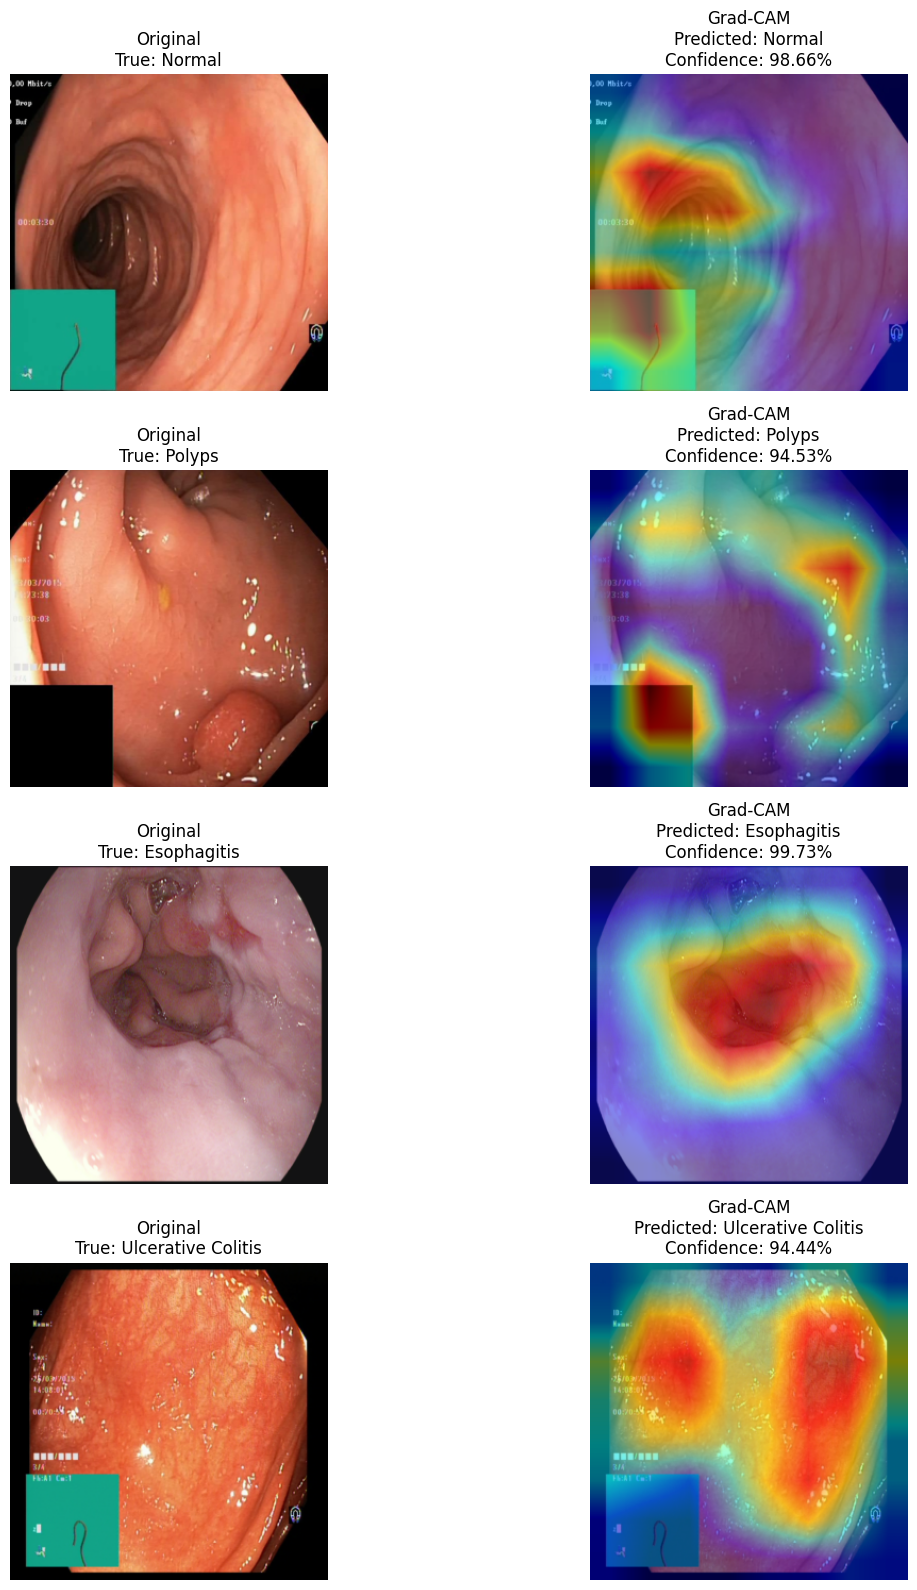

Final Grad-CAM saved to:
/content/drive/MyDrive/GI_Project/Results/final_gradcam_all_classes.png


In [ ]:
# ==========================================
# Final Grad-CAM for all four classes
# ==========================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

sample_indices = {
    "Normal": 1,
    "Polyps": 2,
    "Esophagitis": 5,
    "Ulcerative Colitis": 0
}

class_names = [
    "Normal",
    "Polyps",
    "Esophagitis",
    "Ulcerative Colitis"
]

plt.figure(figsize=(14, 16))

plot_index = 1

for class_name, idx in sample_indices.items():

    # اخذ الصورة وال label
    image_tensor, true_label = test_data[idx]

    # اضافة Batch dimension
    input_tensor = image_tensor.unsqueeze(0).to(device)



    input_tensor.requires_grad_(True)

    # --------------------------
    # Prediction
    # --------------------------
    model.eval()

    with torch.no_grad():

        outputs = model(input_tensor)

        if hasattr(outputs, "logits"):
            outputs = outputs.logits

        probabilities = F.softmax(outputs, dim=1)

        confidence, predicted_label = torch.max(
            probabilities,
            dim=1
        )

    predicted_label = predicted_label.item()
    confidence = confidence.item() * 100

    # --------------------------
    # Grad-CAM
    # --------------------------
    model.zero_grad()

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    # --------------------------
    # اعادة الصورة الى شكلها الطبيعي
    # --------------------------
    image_display = (
        image_tensor
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image_display = image_display * std + mean

    image_display = np.clip(
        image_display,
        0,
        1
    )

    image_display = image_display.astype(
        np.float32
    )

    cam_image = show_cam_on_image(
        image_display,
        grayscale_cam,
        use_rgb=True
    )

    # --------------------------
    # Original Image
    # --------------------------
    plt.subplot(4, 2, plot_index)

    plt.imshow(image_display)

    plt.title(
        f"Original\n"
        f"True: {class_names[true_label]}"
    )

    plt.axis("off")

    plot_index += 1

    # --------------------------
    # Grad-CAM Image
    # --------------------------
    plt.subplot(4, 2, plot_index)

    plt.imshow(cam_image)

    plt.title(
        f"Grad-CAM\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

    plot_index += 1

plt.tight_layout()

final_gradcam_path = (
    "/content/drive/MyDrive/GI_Project/Results/"
    "final_gradcam_all_classes.png"
)

plt.savefig(
    final_gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final Grad-CAM saved to:")
print(final_gradcam_path)

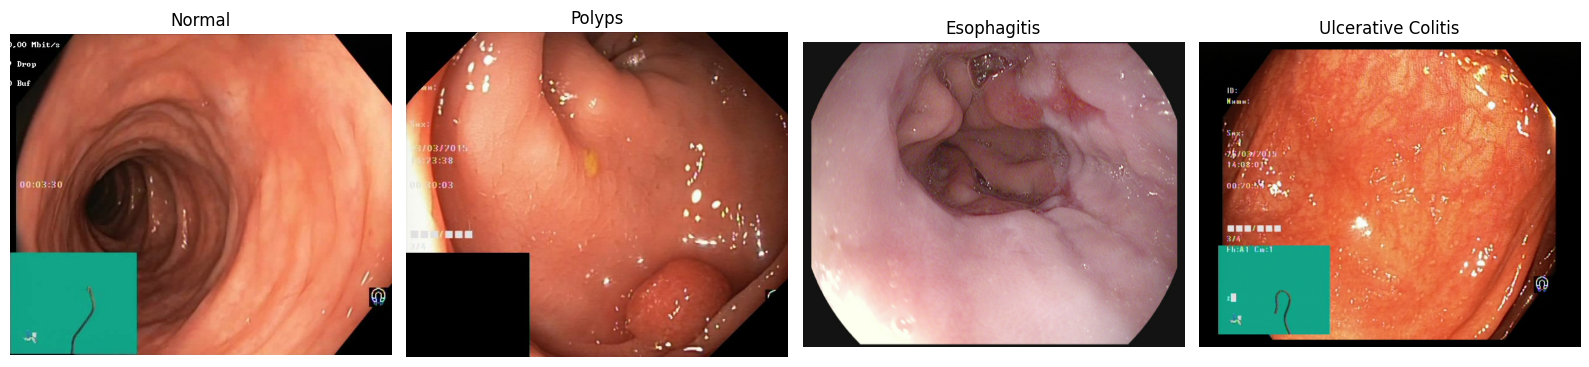

Image saved to: /content/drive/MyDrive/GI_Project/Results/dataset_four_classes.png


In [ ]:
import matplotlib.pyplot as plt


wanted_classes = ["Normal", "Polyps", "Esophagitis", "Ulcerative Colitis"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, class_name in zip(axes, wanted_classes):

    # البحث عن اول صورة من هذه الفئة
    for sample in test_dataset:
        if sample["source"] == class_name:
            image = sample["image"]

            ax.imshow(image)
            ax.set_title(class_name)
            ax.axis("off")
            break

plt.tight_layout()

save_path = "/content/drive/MyDrive/GI_Project/Results/dataset_four_classes.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Image saved to:", save_path)

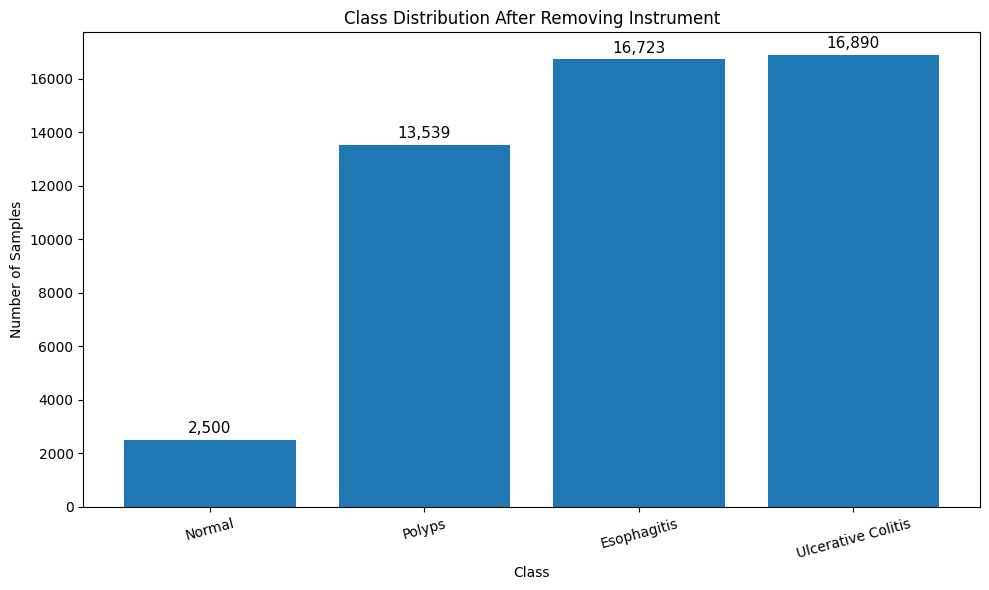

Figure saved to: /content/drive/MyDrive/GI_Project/Results/class_distribution.png


In [ ]:
import matplotlib.pyplot as plt

classes = ["Normal", "Polyps", "Esophagitis", "Ulcerative Colitis"]
counts = [2500, 13539, 16723, 16890]

plt.figure(figsize=(10, 6))

bars = plt.bar(classes, counts)


for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 250,
        f"{count:,}",
        ha="center",
        fontsize=11
    )

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution After Removing Instrument")
plt.xticks(rotation=15)

plt.tight_layout()

save_path = "/content/drive/MyDrive/GI_Project/Results/class_distribution.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", save_path)

In [ ]:
# فحص تكرار img_id داخل balanced_dataset

from collections import Counter, defaultdict

img_ids = balanced_dataset["img_id"]

id_counts = Counter(img_ids)

duplicate_ids = {
    img_id: count
    for img_id, count in id_counts.items()
    if count > 1
}

print("Total samples:", len(balanced_dataset))
print("Unique img_id:", len(set(img_ids)))
print("Duplicated img_id count:", len(duplicate_ids))

# التأكد ان الصورة المكررة لا تحمل اكثر من Class مختلف
id_to_sources = defaultdict(set)

for item in balanced_dataset:
    id_to_sources[item["img_id"]].add(item["source"])

conflicting_ids = {
    img_id: sources
    for img_id, sources in id_to_sources.items()
    if len(sources) > 1
}

print("img_id with conflicting classes:", len(conflicting_ids))

Total samples: 10000
Unique img_id: 5262
Duplicated img_id count: 2241
img_id with conflicting classes: 0


In [ ]:
# حساب عدد الصور الفريدة في كل Class

from collections import defaultdict

class_unique_ids = defaultdict(set)

for item in balanced_dataset:
    class_unique_ids[item["source"]].add(item["img_id"])

print("Unique images per class:")
print("-" * 35)

for class_name, ids in class_unique_ids.items():
    print(f"{class_name}: {len(ids)}")

Unique images per class:
-----------------------------------
Normal: 2500
Ulcerative Colitis: 930
Polyps: 916
Esophagitis: 916


In [ ]:
# انشاء Dataset تحتوي على صورة واحدة فقط لكل img_id

from collections import OrderedDict

unique_indices = OrderedDict()

for index, item in enumerate(balanced_dataset):

    img_id = item["img_id"]

    if img_id not in unique_indices:
        unique_indices[img_id] = index

unique_dataset = balanced_dataset.select(
    list(unique_indices.values())
)

print("Unique Dataset Size:", len(unique_dataset))

Unique Dataset Size: 5262


In [ ]:
# تقسيم الصور الفريدة إلى Train / Validation / Test
# بنسبة 70% / 15% / %15
# مع الحفاظ على توزيع الأصناف

from sklearn.model_selection import train_test_split
from collections import Counter

# ارقام الصفوف
all_indices = list(range(len(unique_dataset)))

# اسماء الأصناف لكل صورة
all_labels = unique_dataset["source"]

# المرحلة الأولى:
# 70% Train و 30% مؤقتة ل Validation + Test
train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42,
    shuffle=True,
    stratify=all_labels
)

# Labels الخاصة بال%30
temp_labels = [all_labels[i] for i in temp_indices]

# المرحلة الثانية:
# تقسيم الـ 30% بالتساوي الى %15 Validation %و 15 Test
valid_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    shuffle=True,
    stratify=temp_labels
)

# انشاء ال Datasets الجديدة
train_dataset = unique_dataset.select(train_indices)
valid_dataset = unique_dataset.select(valid_indices)
test_dataset = unique_dataset.select(test_indices)

print("Train:", len(train_dataset))
print("Validation:", len(valid_dataset))
print("Test:", len(test_dataset))

print("\nTrain classes:", Counter(train_dataset["source"]))
print("Validation classes:", Counter(valid_dataset["source"]))
print("Test classes:", Counter(test_dataset["source"]))

Train: 3683
Validation: 789
Test: 790

Train classes: Counter({'Normal': 1750, 'Ulcerative Colitis': 651, 'Esophagitis': 641, 'Polyps': 641})
Validation classes: Counter({'Normal': 375, 'Ulcerative Colitis': 139, 'Polyps': 138, 'Esophagitis': 137})
Test classes: Counter({'Normal': 375, 'Ulcerative Colitis': 140, 'Esophagitis': 138, 'Polyps': 137})


In [ ]:
# التأكد من عدم وجود نفس الصورة في اكثر من مجموعة

train_ids = set(train_dataset["img_id"])
valid_ids = set(valid_dataset["img_id"])
test_ids = set(test_dataset["img_id"])

print("Train - Validation overlap:",
      len(train_ids.intersection(valid_ids)))

print("Train - Test overlap:",
      len(train_ids.intersection(test_ids)))

print("Validation - Test overlap:",
      len(valid_ids.intersection(test_ids)))

Train - Validation overlap: 0
Train - Test overlap: 0
Validation - Test overlap: 0


In [ ]:
# التحقق من ان جميع الصور داخل كل مجموعة فريدة

print("Unique Train IDs:", len(set(train_dataset["img_id"])))
print("Train Samples:", len(train_dataset))

print("Unique Validation IDs:", len(set(valid_dataset["img_id"])))
print("Validation Samples:", len(valid_dataset))

print("Unique Test IDs:", len(set(test_dataset["img_id"])))
print("Test Samples:", len(test_dataset))

Unique Train IDs: 3683
Train Samples: 3683
Unique Validation IDs: 789
Validation Samples: 789
Unique Test IDs: 790
Test Samples: 790


In [ ]:
# حفظ التقسيم الجديد بدون Data Leakage

from datasets import DatasetDict

new_splits_path = "/content/drive/MyDrive/GI_Project/dataset_splits_no_leakage"

dataset_splits_no_leakage = DatasetDict({
    "train": train_dataset,
    "validation": valid_dataset,
    "test": test_dataset
})

dataset_splits_no_leakage.save_to_disk(new_splits_path)

print("New dataset splits saved successfully!")
print(new_splits_path)

Saving the dataset (0/2 shards):   0%|          | 0/3683 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/789 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/790 [00:00<?, ? examples/s]

New dataset splits saved successfully!
/content/drive/MyDrive/GI_Project/dataset_splits_no_leakage
